# Compare Retrieval Methods with Pinecone — Token 300

This notebook compares five retrieval approaches using the **same `token_300` chunks** and your existing 30-question evaluation set:

1. Dense vector retrieval (Pinecone baseline)
2. BM25 keyword retrieval
3. Hybrid retrieval (dense + BM25 using Reciprocal Rank Fusion)
4. Hybrid + cross-encoder reranking
5. MMR (Maximum Marginal Relevance)

**Fair-comparison rules**
- Keep the same corpus, questions, expected answers, and `top_k`.
- Use the same Llama embedding model (`llama-text-embed-v2`, 384 dimensions) for semantic evaluation.
- BM25 scores, Pinecone scores, and reranker scores are different score types. Do not compare their raw values directly.
- The semantic relevance score below is a proxy: it measures similarity between each retrieved chunk and the expected answer. It is not a guaranteed correctness score.


## 1. Install dependencies

Run this cell once in the notebook environment. If you already have these packages, you can skip installation.

In [1]:
%pip install -q pinecone rank-bm25 sentence-transformers pandas numpy matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Connect your existing Pinecone index and load your existing data

This notebook cannot automatically access Python variables from another notebook. In the next cell, either:
- paste your existing Pinecone connection/index setup, or
- keep the setup below and enter your API key when prompted.

Then make sure `chunk_sets["token_300"]` and `evaluation_set` are available. Copy those variables from your current notebook if needed.

Your `evaluation_set` should contain dictionaries with `question` and `expected_answer` keys. The `keywords` field can remain; this notebook does not use keyword checking.

In [2]:
evaluation_set = [
    {
        "question": "What is Python?",
        "expected_answer": "Python is an easy to learn and powerful programming language.",
        "keywords": ["easy to learn", "powerful", "programming language"]
    },
    {
        "question": "Why is Python useful?",
        "expected_answer": "Python helps automate tasks and rapid application development.",
        "keywords": ["automate", "rapid application development"]
    },
    {
        "question": "What are the advantages of Python?",
        "expected_answer": "Python offers high-level data structures, object-oriented programming, and interpreted execution.",
        "keywords": ["high-level", "object-oriented", "interpreted"]
    },
    {
        "question": "What is the Python interpreter?",
        "expected_answer": "The interpreter executes Python code interactively or from scripts.",
        "keywords": ["interpreter", "execute", "scripts"]
    },
    {
        "question": "What is interactive mode?",
        "expected_answer": "Interactive mode allows commands to be executed immediately from the prompt.",
        "keywords": ["interactive", "prompt", "commands"]
    },
    {
        "question": "What encoding is used by default in Python source files?",
        "expected_answer": "UTF-8.",
        "keywords": ["UTF-8"]
    },
    {
        "question": "What is floor division?",
        "expected_answer": "Floor division uses // and discards the fractional part.",
        "keywords": ["//", "fractional part"]
    },
    {
        "question": "How do you calculate powers in Python?",
        "expected_answer": "The ** operator is used for exponentiation.",
        "keywords": ["**", "power"]
    },
    {
        "question": "What error occurs when an undefined variable is used?",
        "expected_answer": "NameError.",
        "keywords": ["NameError"]
    },
    {
        "question": "How are strings created in Python?",
        "expected_answer": "Strings can be enclosed in single or double quotes.",
        "keywords": ["single quotes", "double quotes"]
    },
    {
        "question": "What is string slicing?",
        "expected_answer": "Slicing extracts a portion of a string using index ranges.",
        "keywords": ["slice", "substring"]
    },
    {
        "question": "Why are strings immutable?",
        "expected_answer": "String contents cannot be modified after creation.",
        "keywords": ["immutable", "cannot be changed"]
    },
    {
        "question": "What is a list in Python?",
        "expected_answer": "A mutable sequence used to store collections of values.",
        "keywords": ["mutable", "sequence"]
    },
    {
        "question": "What does append() do?",
        "expected_answer": "Adds an element to the end of a list.",
        "keywords": ["append", "end of list"]
    },
    {
        "question": "What is the difference between mutable and immutable objects?",
        "expected_answer": "Mutable objects can be modified while immutable objects cannot.",
        "keywords": ["mutable", "immutable"]
    },
    {
        "question": "How does a while loop work?",
        "expected_answer": "It executes while a condition remains true.",
        "keywords": ["while", "condition"]
    },
    {
        "question": "What is an if statement used for?",
        "expected_answer": "Conditional execution of code.",
        "keywords": ["condition", "branching"]
    },
    {
        "question": "How does a for loop work in Python?",
        "expected_answer": "It iterates over items in a sequence.",
        "keywords": ["iterate", "sequence"]
    },
    {
        "question": "What is the purpose of range()?",
        "expected_answer": "Generate a sequence of numbers.",
        "keywords": ["range", "sequence of numbers"]
    },
    {
        "question": "What does break do?",
        "expected_answer": "Terminates the nearest loop.",
        "keywords": ["break", "loop"]
    },
    {
        "question": "What does continue do?",
        "expected_answer": "Skips the remaining code and starts the next iteration.",
        "keywords": ["continue", "next iteration"]
    },
    {
        "question": "What is the pass statement?",
        "expected_answer": "A placeholder statement that performs no action.",
        "keywords": ["pass", "placeholder"]
    },
    {
        "question": "What is a function?",
        "expected_answer": "A reusable block of code defined using def.",
        "keywords": ["function", "def"]
    },
    {
        "question": "What is a docstring?",
        "expected_answer": "A string used to document a function, class, or module.",
        "keywords": ["docstring", "documentation"]
    },
    {
        "question": "What are default arguments?",
        "expected_answer": "Arguments that have predefined values.",
        "keywords": ["default argument"]
    },
    {
        "question": "What are keyword arguments?",
        "expected_answer": "Arguments passed using parameter names.",
        "keywords": ["keyword argument"]
    },
    {
        "question": "What is a lambda function?",
        "expected_answer": "A small anonymous function created with lambda.",
        "keywords": ["lambda", "anonymous function"]
    },
    {
        "question": "What is a tuple?",
        "expected_answer": "An immutable sequence of values.",
        "keywords": ["tuple", "immutable"]
    },
    {
        "question": "What is a set?",
        "expected_answer": "An unordered collection of unique elements.",
        "keywords": ["set", "unique"]
    },
    {
        "question": "What is a dictionary?",
        "expected_answer": "A collection of key-value pairs.",
        "keywords": ["dictionary", "key", "value"]
    }
]

In [3]:

import time
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from dotenv import load_dotenv
from pinecone import Pinecone
from rank_bm25 import BM25Okapi

load_dotenv()

PINECONE_API_KEY = os.getenv("PINECONE_KEY")
INDEX_NAME = "documents-minilm"

pc = Pinecone(api_key=PINECONE_API_KEY)
index = pc.Index(INDEX_NAME)

NAMESPACE = "token_300"
TOP_K = 3
CANDIDATE_K = 15

print("Pinecone connected successfully!")


Pinecone connected successfully!


In [4]:
NAMESPACE = "token_300"
TOP_K = 3
CANDIDATE_K = 15

documents = list(
    index.documents.list(
        namespace=NAMESPACE,
        limit=100
    )
)

document_ids = [doc.id for doc in documents]

token_300_chunks = []

for start in range(0, len(document_ids), 100):
    batch_ids = document_ids[start:start + 100]

    response = index.documents.fetch(
        namespace=NAMESPACE,
        ids=batch_ids,
        include_fields=["chunk_text", "title"]
    )

    for doc in response.documents.values():
        if doc.chunk_text:
            token_300_chunks.append(doc.chunk_text)

print("Total chunks:", len(token_300_chunks))
print("Total evaluation questions:", len(evaluation_set))
print("First chunk:", token_300_chunks[0][:300])

Total chunks: 309
Total evaluation questions: 30
First chunk:  = name # instance variable unique to each instance
>>> d = Dog('Fido')
>>> e = Dog('Buddy')
>>> d.kind # shared by all dogs
'canine'
>>> e.kind # shared by all dogs
'canine'
>>> d.name # unique to d
'Fido'
>>> e.name # unique to e
'Buddy'
74 Chapter 9. Classes\nPython Tutorial, Release 3.7.0
As dis


## 3. Define the embedding helper

Use the same Llama embedding configuration you used in your Pinecone experiment. Pinecone's integrated embedding search embeds queries automatically; this helper is used for semantic evaluation and MMR.

If you already defined `encode_texts` with this exact model and dimension in your earlier notebook, you can keep that function and skip redefining it.

In [5]:
MODEL_NAME = "llama-text-embed-v2"
EMBEDDING_DIMENSION = 384

def encode_texts(texts, input_type="passage"):
    response = pc.inference.embed(
        model=MODEL_NAME,
        inputs=[str(text) for text in texts],
        parameters={
            "input_type": input_type,
            "dimension": EMBEDDING_DIMENSION
        }
    )
    return [item.values for item in response]

def cosine_similarity(vec1, vec2):
    vec1 = np.asarray(vec1, dtype=np.float32)
    vec2 = np.asarray(vec2, dtype=np.float32)
    denom = np.linalg.norm(vec1) * np.linalg.norm(vec2)
    if denom == 0:
        return 0.0
    return float(np.dot(vec1, vec2) / denom)

## 4. Common result format and Pinecone dense search

All retrieval methods will return a list of dictionaries with a `chunk` and a `score`. The score is retained for debugging, but the final comparison uses the common semantic evaluation.

The helper below handles common Pinecone SDK document representations. If it cannot find the chunk text, inspect one result with `print(results.matches[0].to_dict())` and adjust `get_match_text()` to match your SDK response.

In [6]:
def get_match_text(match):
    # Try direct document attribute first.
    text_value = getattr(match, "chunk_text", None)
    if text_value:
        return str(text_value)

    # Fall back to the SDK's dictionary representation.
    if hasattr(match, "to_dict"):
        data = match.to_dict()
    elif isinstance(match, dict):
        data = match
    else:
        data = {}

    for key in ("chunk_text", "text", "content"):
        if data.get(key):
            return str(data[key])

    # Some SDK versions nest returned fields.
    for container_key in ("fields", "metadata", "document"):
        nested = data.get(container_key)
        if isinstance(nested, dict):
            for key in ("chunk_text", "text", "content"):
                if nested.get(key):
                    return str(nested[key])

    return None

def search_dense(question, top_k=TOP_K):
    results = index.documents.search(
        namespace=NAMESPACE,
        top_k=top_k,
        score_by=[{
            "type": "embed",
            "fields": ["chunk_text"],
            "query": question
        }],
        include_fields=["title", "chunk_text"]
    )

    retrieved = []
    for match in results.matches:
        chunk = get_match_text(match)
        if chunk:
            raw = match.to_dict() if hasattr(match, "to_dict") else {}
            score = raw.get("_score", raw.get("score")) if isinstance(raw, dict) else None
            retrieved.append({"chunk": chunk, "score": score})
    return retrieved

# Quick smoke test
dense_test = search_dense(evaluation_set[0]["question"], top_k=TOP_K)
print("Dense results:", len(dense_test))
for rank, item in enumerate(dense_test, 1):
    print(f"\nRank {rank}: {item['chunk'][:250]}")

Dense results: 3

Rank 1:  take a lot of development time to get even a ﬁrst-draft program.
Python is simpler to use, available on Windows, Mac OS X, and Unix operating systems, and will help you
get the job done more quickly.
Python is simple to use, but it is a real program

Rank 2:  sockets, and even interfaces to graphical user interface toolkits like Tk.
Python is an interpreted language, which can save you considerable time during program development
because no compilation and linking is necessary. The interpreter can be use

Rank 3:  the Python interpreter into an application written in C and use it as an
extension or command language for that application.
By the way, the language is named after the BBC show “Monty Python’s Flying Circus” and has nothing
to do with reptiles. Mak


## 5. BM25 keyword retrieval

BM25 ranks chunks using the words shared by the question and each chunk. It does not use embeddings.

We use a simple lowercase word tokenizer as a transparent baseline.

In [7]:
def tokenize(text):
    return re.findall(r"\b\w+\b", str(text).lower())

tokenized_corpus = [tokenize(chunk) for chunk in token_300_chunks]
bm25 = BM25Okapi(tokenized_corpus)

def search_bm25(question, top_k=TOP_K):
    scores = bm25.get_scores(tokenize(question))
    top_indices = np.argsort(scores)[::-1][:top_k]
    return [
        {"chunk": str(token_300_chunks[i]), "score": float(scores[i]), "index": int(i)}
        for i in top_indices
        if scores[i] > 0
    ]

bm25_test = search_bm25(evaluation_set[0]["question"], TOP_K)
print("BM25 results:", len(bm25_test))
for rank, item in enumerate(bm25_test, 1):
    print(f"\nRank {rank} | BM25 score: {item['score']:.4f}")
    print(item["chunk"][:250])

BM25 results: 3

Rank 1 | BM25 score: 7.4615
 3.7.0
pip has many more options. Consult the installing-index guide for complete documentation for pip. When
you’vewrittenapackageandwanttomakeitavailableonthePythonPackageIndex, consultthedistributing-
index guide.
100 Chapter 12. Virtual Environme

Rank 2 | BM25 score: 7.1177
 through dictionaries, the key and corresponding value can be retrieved at the same time using
the items() method.
>>> knights = {'gallahad': 'the pure', 'robin': 'the brave'}
>>> for k, v in knights.items():
... print(k, v)
...
gallahad the pure
rob

Rank 3 | BM25 score: 6.9044
thing as MyClass.f — it is a method object, not a function object.
9.3. A First Look at Classes 73\nPython Tutorial, Release 3.7.0
9.3.4 Method Objects
Usually, a method is called right after it is bound:
x.f()
In the MyClass example, this will retur


## 6. Hybrid retrieval using Reciprocal Rank Fusion (RRF)

Hybrid retrieval combines dense and BM25 rankings. Their raw scores are on different scales, so we use **Reciprocal Rank Fusion** instead of adding raw scores.

RRF gives each result a contribution based on its rank in each list. A chunk ranked highly by both methods is likely to receive a stronger fused rank.

In [8]:
def reciprocal_rank_fusion(result_lists, k=60, top_k=TOP_K):
    fused_scores = {}
    chunk_by_key = {}

    for results in result_lists:
        for rank, item in enumerate(results, start=1):
            chunk = item["chunk"]
            key = chunk
            fused_scores[key] = fused_scores.get(key, 0.0) + 1.0 / (k + rank)
            chunk_by_key[key] = chunk

    ordered = sorted(fused_scores, key=fused_scores.get, reverse=True)[:top_k]
    return [{"chunk": chunk_by_key[key], "score": fused_scores[key]} for key in ordered]

def search_hybrid(question, top_k=TOP_K, candidate_k=CANDIDATE_K):
    dense_results = search_dense(question, top_k=candidate_k)
    bm25_results = search_bm25(question, top_k=candidate_k)
    return reciprocal_rank_fusion(
        [dense_results, bm25_results],
        top_k=top_k
    )

hybrid_test = search_hybrid(evaluation_set[0]["question"])
print("Hybrid results:", len(hybrid_test))
for rank, item in enumerate(hybrid_test, 1):
    print(f"\nRank {rank} | RRF score: {item['score']:.5f}")
    print(item["chunk"][:250])

Hybrid results: 3

Rank 1 | RRF score: 0.01639
 take a lot of development time to get even a ﬁrst-draft program.
Python is simpler to use, available on Windows, Mac OS X, and Unix operating systems, and will help you
get the job done more quickly.
Python is simple to use, but it is a real program

Rank 2 | RRF score: 0.01639
 3.7.0
pip has many more options. Consult the installing-index guide for complete documentation for pip. When
you’vewrittenapackageandwanttomakeitavailableonthePythonPackageIndex, consultthedistributing-
index guide.
100 Chapter 12. Virtual Environme

Rank 3 | RRF score: 0.01613
 sockets, and even interfaces to graphical user interface toolkits like Tk.
Python is an interpreted language, which can save you considerable time during program development
because no compilation and linking is necessary. The interpreter can be use


## 7. Hybrid retrieval + reranking

First, hybrid retrieval gathers a wider set of candidates. A cross-encoder then reads each question–chunk pair together and assigns a relevance score. We sort by that score and keep the top 3.

The first run may download the model. This uses a small general-purpose MS MARCO cross-encoder as a baseline.

In [9]:
from sentence_transformers import CrossEncoder

RERANKER_NAME = "cross-encoder/ms-marco-MiniLM-L-6-v2"
reranker = CrossEncoder(RERANKER_NAME)

def search_hybrid_reranked(question, top_k=TOP_K, candidate_k=CANDIDATE_K):
    candidates = search_hybrid(question, top_k=candidate_k, candidate_k=candidate_k)
    if not candidates:
        return []

    pairs = [(question, item["chunk"]) for item in candidates]
    rerank_scores = reranker.predict(pairs)

    reranked = [
        {"chunk": item["chunk"], "score": float(score)}
        for item, score in zip(candidates, rerank_scores)
    ]
    reranked.sort(key=lambda x: x["score"], reverse=True)
    return reranked[:top_k]

reranked_test = search_hybrid_reranked(evaluation_set[0]["question"])
print("Hybrid + reranker results:", len(reranked_test))
for rank, item in enumerate(reranked_test, 1):
    print(f"\nRank {rank} | Reranker score: {item['score']:.4f}")
    print(item["chunk"][:250])

c:\Users\KeerthanaV\Desktop\Projects\rag_app\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 105/105 [00:00<00:00, 1420.68it/s]


Hybrid + reranker results: 3

Rank 1 | Reranker score: 6.1255
 sockets, and even interfaces to graphical user interface toolkits like Tk.
Python is an interpreted language, which can save you considerable time during program development
because no compilation and linking is necessary. The interpreter can be use

Rank 2 | Reranker score: 4.5817
 take a lot of development time to get even a ﬁrst-draft program.
Python is simpler to use, available on Windows, Mac OS X, and Unix operating systems, and will help you
get the job done more quickly.
Python is simple to use, but it is a real program

Rank 3 | Reranker score: 1.0004
 of the Python language,
rather than implementing code using concepts common to other languages. For example, a common
idiom in Python is to loop over all elements of an iterable using a for statement. Many other languages
don’t have this type of con


## 8. MMR — Maximum Marginal Relevance

MMR aims to balance:
- **Relevance:** how closely a chunk matches the question.
- **Diversity:** how different a chunk is from chunks already selected.

It first retrieves a candidate pool using dense search, embeds the question and candidates, then selects chunks one by one while penalizing redundancy.

`MMR_LAMBDA` controls the balance:
- closer to `1.0`: prioritize relevance
- closer to `0.0`: prioritize diversity

We start with `0.7`.

In [10]:
MMR_LAMBDA = 0.7

def search_mmr(question, top_k=TOP_K, candidate_k=CANDIDATE_K, lambda_mult=MMR_LAMBDA):
    candidates = search_dense(question, top_k=candidate_k)
    if not candidates:
        return []

    candidate_texts = [item["chunk"] for item in candidates]
    vectors = np.asarray(encode_texts(candidate_texts, input_type="passage"), dtype=np.float32)
    query_vector = np.asarray(encode_texts([question], input_type="query")[0], dtype=np.float32)

    relevance = np.array([cosine_similarity(query_vector, vec) for vec in vectors])
    selected_indices = []
    remaining = list(range(len(candidate_texts)))

    while remaining and len(selected_indices) < top_k:
        mmr_scores = []
        for idx in remaining:
            if not selected_indices:
                diversity_penalty = 0.0
            else:
                diversity_penalty = max(
                    cosine_similarity(vectors[idx], vectors[chosen])
                    for chosen in selected_indices
                )
            mmr_score = (
                lambda_mult * relevance[idx]
                - (1 - lambda_mult) * diversity_penalty
            )
            mmr_scores.append((mmr_score, idx))

        _, best_idx = max(mmr_scores, key=lambda pair: pair[0])
        selected_indices.append(best_idx)
        remaining.remove(best_idx)

    return [
        {"chunk": candidate_texts[i], "score": float(relevance[i])}
        for i in selected_indices
    ]

mmr_test = search_mmr(evaluation_set[0]["question"])
print("MMR results:", len(mmr_test))
for rank, item in enumerate(mmr_test, 1):
    print(f"\nRank {rank} | Query relevance: {item['score']:.4f}")
    print(item["chunk"][:250])

MMR results: 3

Rank 1 | Query relevance: 0.4532
 take a lot of development time to get even a ﬁrst-draft program.
Python is simpler to use, available on Windows, Mac OS X, and Unix operating systems, and will help you
get the job done more quickly.
Python is simple to use, but it is a real program

Rank 2 | Query relevance: 0.3853
.7.0 or any part thereof, and wants to make the
derivative work available to others as provided herein, then Licensee hereby
agrees to include in any such work a brief summary of the changes made to Python
3.7.0.
4. PSF is making Python 3.7.0 availab

Rank 3 | Query relevance: 0.4031
 be accessed through multiple paths from the
bottommost class). For example, all classes inherit from object, so any case of multiple inheritance
provides more than one path to reach object. To keep the base classes from being accessed more than
once


## 9. Evaluate all five methods with the same evaluation set

For each question, retrieve the top 3 chunks and compare each chunk with the expected answer using the same Llama embedding model. We report:
- `best_semantic_similarity`: best of the retrieved chunks
- `mean_semantic_similarity`: mean across the retrieved chunks
- `retrieval_time_sec`: time spent retrieving/reranking (embedding calls for evaluation are excluded)

This makes the semantic proxy comparable across methods, but it is still not a substitute for human relevance labels or answer-quality evaluation.

In [11]:
RELEVANCE_THRESHOLD = 0.50
TOP_K = 3

In [12]:
def calculate_recall_at_k(relevance, k=3):
    relevant_count = sum(relevance)

    if relevant_count == 0:
        return 0.0

    retrieved_relevant = sum(relevance[:k])

    return retrieved_relevant / relevant_count


def calculate_mrr_at_k(relevance, k=3):
    for rank, is_relevant in enumerate(relevance[:k], start=1):
        if is_relevant:
            return 1 / rank

    return 0.0


def calculate_ndcg_at_k(relevance, k=3):
    import numpy as np

    dcg = sum(
        rel / np.log2(rank + 1)
        for rank, rel in enumerate(relevance[:k], start=1)
    )

    ideal = sorted(relevance, reverse=True)[:k]

    idcg = sum(
        rel / np.log2(rank + 1)
        for rank, rel in enumerate(ideal, start=1)
    )

    return dcg / idcg if idcg > 0 else 0.0

In [13]:
def evaluate_retriever(method_name, retrieve_fn, evaluation_set):
    rows = []

    for item in evaluation_set:
        question = item["question"]
        expected_answer = item["expected_answer"]

        start = time.perf_counter()
        retrieved = retrieve_fn(question)
        elapsed = time.perf_counter() - start

        chunks = [
            r["chunk"] for r in retrieved
            if r.get("chunk")
        ]

        if chunks:
            vectors = encode_texts(
                [expected_answer] + chunks,
                input_type="passage"
            )

            expected_vec = vectors[0]

            similarities = [
                cosine_similarity(expected_vec, vec)
                for vec in vectors[1:]
            ]

            best_score = max(similarities)
            mean_score = float(np.mean(similarities))

            # Automatic approximate relevance labels
            relevance = [
                1 if score >= RELEVANCE_THRESHOLD else 0
                for score in similarities
            ]

            recall = calculate_recall_at_k(relevance, TOP_K)
            mrr = calculate_mrr_at_k(relevance, TOP_K)
            ndcg = calculate_ndcg_at_k(relevance, TOP_K)

        else:
            best_score = 0.0
            mean_score = 0.0
            relevance = []
            recall = 0.0
            mrr = 0.0
            ndcg = 0.0

        rows.append({
            "method": method_name,
            "question": question,
            "best_semantic_similarity": best_score,
            "mean_semantic_similarity": mean_score,
            "recall_at_3": recall,
            "mrr_at_3": mrr,
            "ndcg_at_3": ndcg,
            "retrieval_time_sec": elapsed,
            "relevance_labels": relevance,
            "retrieved_chunks": chunks
        })

    return rows

In [14]:
RETRIEVERS = {
    "Dense": lambda q: search_dense(q, TOP_K),
    "BM25": lambda q: search_bm25(q, TOP_K),
    "Hybrid (RRF)": lambda q: search_hybrid(q, TOP_K, CANDIDATE_K),
    "Hybrid + Reranker": lambda q: search_hybrid_reranked(q, TOP_K, CANDIDATE_K),
    "MMR": lambda q: search_mmr(q, TOP_K, CANDIDATE_K, MMR_LAMBDA),
}

In [15]:
all_rows = []

for method_name, retrieve_fn in RETRIEVERS.items():
    print(f"Evaluating {method_name}...")

    all_rows.extend(
        evaluate_retriever(
            method_name,
            retrieve_fn,
            evaluation_set
        )
    )

details_df = pd.DataFrame(all_rows)

print("Evaluation complete:", len(details_df))

Evaluating Dense...
Evaluating BM25...
Evaluating Hybrid (RRF)...
Evaluating Hybrid + Reranker...
Evaluating MMR...
Evaluation complete: 150


Semantic evaluation
- Best Semantic Similarity
- Mean Semantic Similarity

Ranking evaluation
- Recall@3
- MRR@3
- nDCG@3

Performance evaluation

- Retrieval Latency

In [16]:
summary_df = (
    details_df.groupby("method")
    .agg(
        avg_best_similarity=(
            "best_semantic_similarity", "mean"
        ),
        avg_mean_similarity=(
            "mean_semantic_similarity", "mean"
        ),
        avg_recall_at_3=("recall_at_3", "mean"),
        avg_mrr_at_3=("mrr_at_3", "mean"),
        avg_ndcg_at_3=("ndcg_at_3", "mean"),
        avg_latency=("retrieval_time_sec", "mean")
    )
    .reset_index()
    .sort_values("avg_ndcg_at_3", ascending=False)
)

summary_df

,method,avg_best_similarity,avg_mean_similarity,avg_recall_at_3,avg_mrr_at_3,avg_ndcg_at_3,avg_latency
1,Dense,0.420252,0.367031,0.200000,0.183333,0.187698,0.422971
4,MMR,0.414399,0.335534,0.166667,0.166667,0.166667,1.173541
2,Hybrid (RRF),0.413434,0.354231,0.166667,0.127778,0.135022,0.325341
3,Hybrid + Reranker,0.402098,0.353270,0.133333,0.100000,0.108729,2.250634
0,BM25,0.370703,0.294056,0.033333,0.016667,0.021031,0.001417


## 10. Compare overall results

The table below averages the per-question scores. Treat the semantic similarity columns as the main common comparison. Retrieval time is useful too, but timings can vary due to network, model downloads, and caching.

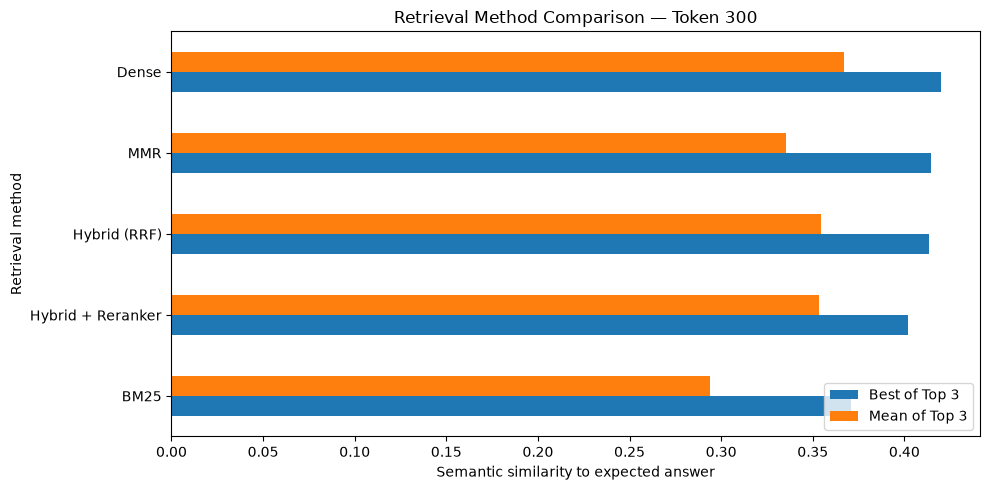

In [17]:
fig, ax = plt.subplots(figsize=(10, 5))

summary_df.sort_values("avg_best_similarity").plot(
    x="method",
    y=["avg_best_similarity", "avg_mean_similarity"],
    kind="barh",
    ax=ax
)

ax.set_xlabel("Semantic similarity to expected answer")
ax.set_ylabel("Retrieval method")
ax.set_title("Retrieval Method Comparison — Token 300")
ax.legend(["Best of Top 3", "Mean of Top 3"])

plt.tight_layout()
plt.show()

## 11. RAGAS EVALUATION


In [18]:
%pip install --force-reinstall --no-deps ragas==0.3.8

  Using cached ragas-0.3.8-py3-none-any.whl.metadata (22 kB)
Using cached ragas-0.3.8-py3-none-any.whl (337 kB)
  Attempting uninstall: ragas
    Found existing installation: ragas 0.4.4
    Uninstalling ragas-0.4.4:
      Successfully uninstalled ragas-0.4.4
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 12. Inspect individual questions
Use this to understand *why* one method performs better or worse. Change `QUESTION_NUMBER` to inspect another evaluation question.

In [19]:
QUESTION_NUMBER = 0  # zero-based: 0 means the first question

question_text = evaluation_set[QUESTION_NUMBER]["question"]
print("Question:", question_text)
print("Expected answer:", evaluation_set[QUESTION_NUMBER]["expected_answer"])

for method_name in RETRIEVERS:
    row = details_df[
        (details_df["method"] == method_name) &
        (details_df["question"] == question_text)
    ].iloc[0]

    print("\n" + "=" * 90)
    print(method_name)
    print("Best semantic similarity:", round(row["best_semantic_similarity"], 4))
    for rank, chunk in enumerate(row["retrieved_chunks"], 1):
        print(f"\nRank {rank}: {chunk[:500]}")

Question: What is Python?
Expected answer: Python is an easy to learn and powerful programming language.

Dense
Best semantic similarity: 0.5623

Rank 1:  take a lot of development time to get even a ﬁrst-draft program.
Python is simpler to use, available on Windows, Mac OS X, and Unix operating systems, and will help you
get the job done more quickly.
Python is simple to use, but it is a real programming language, oﬀering much more structure and support
for large programs than shell scripts or batch ﬁles can oﬀer. On the other hand, Python also oﬀers much
more error checking than C, and, being a very-high-level language, it has high-level data t

Rank 2:  sockets, and even interfaces to graphical user interface toolkits like Tk.
Python is an interpreted language, which can save you considerable time during program development
because no compilation and linking is necessary. The interpreter can be used interactively, which makes it
easy to experiment with features of the language, to w